# AquaPense fish detection — RTX 3050 CUDA

Review COCO annotations, convert to one fish class, fine-tune pretrained YOLO11n, and evaluate the best validation checkpoint on the held-out test set. The source files are preserved. Results cannot be guaranteed; inspect the audit and predictions.

This dataset has only 215 images. Related frames across splits can make metrics optimistic. Split by recording/session before claiming performance on unseen conditions.

Training uses 640 px inputs, batch 4, mixed precision, and zero data-loader workers for Windows/4 GB VRAM. Up to 120 epochs with validation early stopping. Do not tune on test results.

In [1]:
from pathlib import Path
import sys, json
import torch
from IPython.display import display, Image
from aquapense_training import prepare, train, evaluate, audit_summary, OUTPUT
assert torch.cuda.is_available(), "CUDA is required; this notebook never silently uses CPU."
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

Python: C:\Users\AFAN\AppData\Local\Programs\Python\Python311\python.exe
PyTorch: 2.7.1+cu118 CUDA: 11.8
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM GiB: 4.0


## Dataset and annotation review
Checks dimensions, readable images, bounding boxes, orphan annotations, exact cross-split duplicates and perceptual similarity warnings. An unused COCO parent category is excluded. Near-duplicate warnings need visual review.

{
  "splits": {
    "train": {
      "images": 151,
      "boxes": 2490,
      "empty_images": 0,
      "image_sizes": {
        "[2880, 1616]": 151
      },
      "boxes_under_16px_at_640": 234
    },
    "valid": {
      "images": 43,
      "boxes": 712,
      "empty_images": 0,
      "image_sizes": {
        "[2880, 1616]": 43
      },
      "boxes_under_16px_at_640": 77
    },
    "test": {
      "images": 21,
      "boxes": 353,
      "empty_images": 0,
      "image_sizes": {
        "[2880, 1616]": 21
      },
      "boxes_under_16px_at_640": 33
    }
  },
  "errors": [],
  "exact_cross_split_duplicates": [],
  "near_cross_split_duplicates": {
    "count": 6347,
    "examples": [
      [
        "train",
        "frame_2026-11-11_11-44-10_jpg.rf.1OvIlAwOBRXYj8QkK6Ud.jpg",
        "valid",
        "frame_2026-11-11_11-40-20_jpg.rf.24W4cI4O8HKTto6qIODL.jpg",
        2
      ],
      [
        "train",
        "frame_2026-11-11_11-22-00_jpg.rf.1iTEQlBiF51EHnEuxaXL.jpg",
        "val

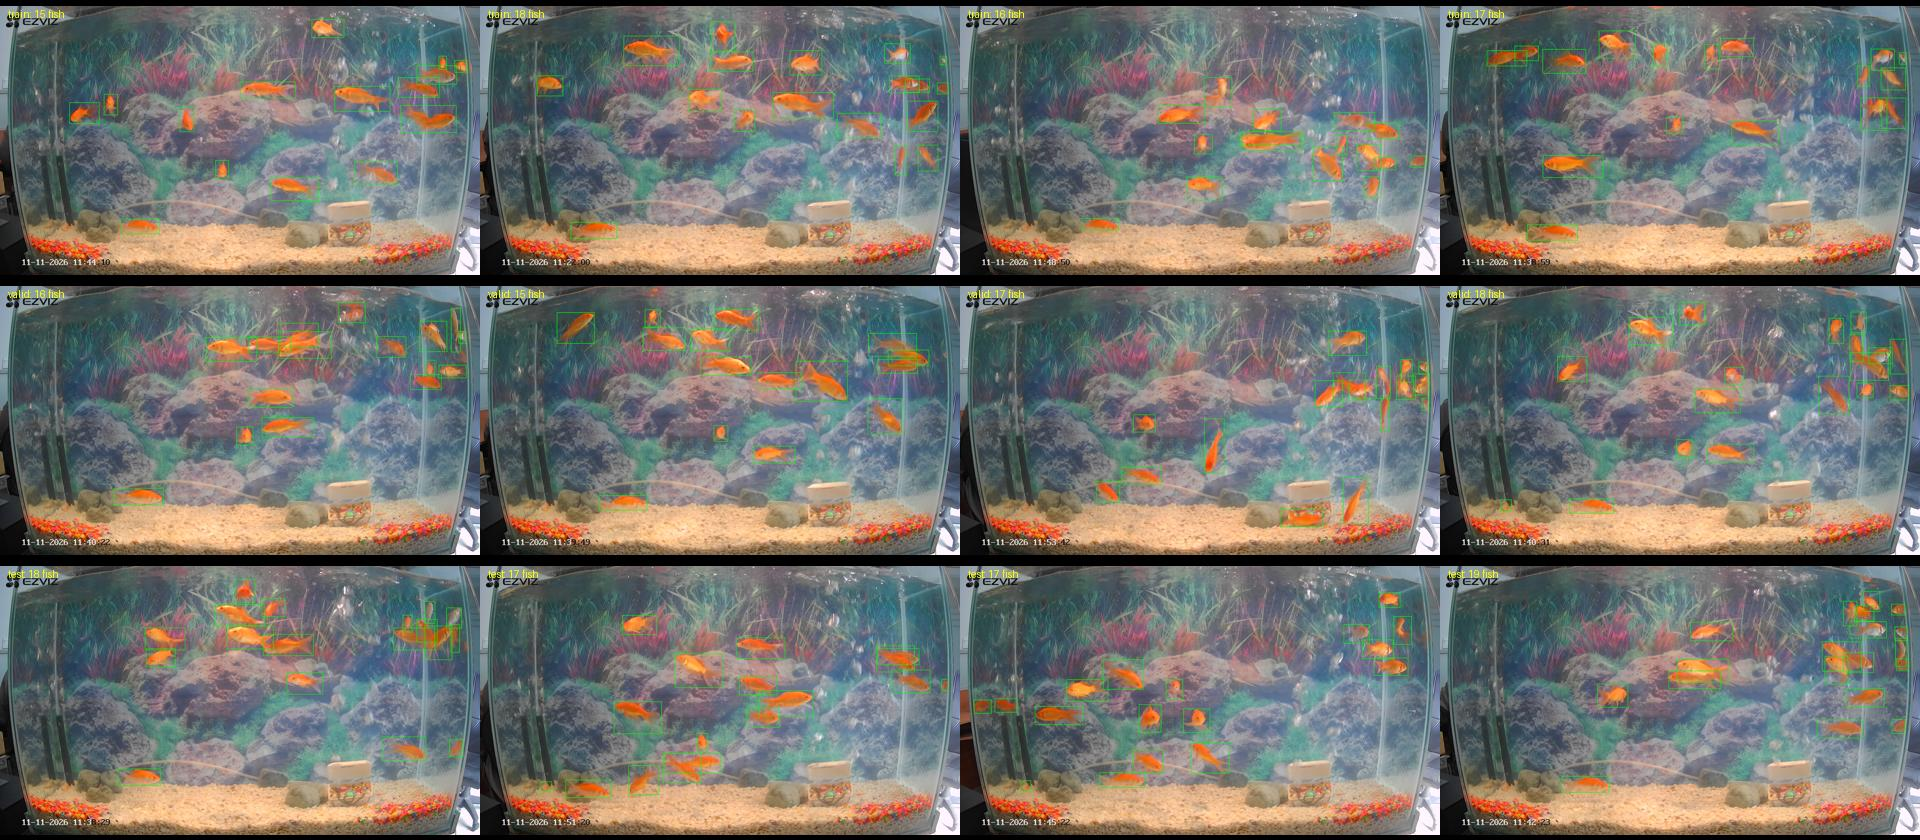

In [2]:
audit = prepare()
print(json.dumps(audit_summary(audit), indent=2))
display(Image(filename=str(OUTPUT / "annotation_review.jpg")))

## Train using CUDA
The pretrained weights download on first use. Training saves the best checkpoint, losses, precision/recall curves, and validation predictions under results. Training can take a while on the laptop GPU. Keep it plugged in. Re-running this cell starts a new run.

In [3]:
best_checkpoint = train(epochs=120)
print("Best checkpoint:", best_checkpoint)

WARNING user config directory 'C:\Users\AFAN\Downloads\FYP\Training\.yolo_config\Ultralytics' is not writable, using 'C:\Users\AFAN\Downloads\FYP\Training\Ultralytics'. Set YOLO_CONFIG_DIR to override.


Creating new Ultralytics Settings v0.0.6 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\AFAN\Downloads\FYP\Training\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


GPU: NVIDIA GeForce RTX 3050 Laptop GPU PyTorch: 2.7.1+cu118


WARNING Download failure, retrying 1/3 https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt... <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get issuer certificate (_ssl.c:1006)>


New https://pypi.org/project/ultralytics/8.4.213 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.7  Python-3.11.7 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


... (4,288 outputs left out)

                   all         43        712      0.963      0.935       0.98      0.725


Speed: 0.3ms preprocess, 5.3ms inference, 0.0ms loss, 2.9ms postprocess per image


Results saved to C:\Users\AFAN\Downloads\FYP\Training\results\fish_detector


Best checkpoint: C:\Users\AFAN\Downloads\FYP\Training\results\fish_detector\weights\best.pt


## Final evaluation
Validation selects the checkpoint; test is evaluated after training. mAP50–95 is stricter than mAP50. Inspect false positives, missed fish and overlapping boxes alongside metrics.

In [4]:
metrics = evaluate(best_checkpoint)
print(json.dumps(metrics, indent=2))

Ultralytics 8.4.7  Python-3.11.7 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access  (ping: 0.10.0 ms, read: 1849.1274.2 MB/s, size: 1086.8 KB)


val: Scanning C:\Users\AFAN\Downloads\FYP\Training\prepared_data\labels\val.cache... 43 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43/43  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 9% ━─────────── 1/11 1.3s/it 0.4s<12.9s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 18% ━━────────── 2/11 2.9it/s 0.5s<3.1s

... (45 outputs left out)

image 21/21 C:\Users\AFAN\Downloads\FYP\Training\prepared_data\images\test\00020.jpg: 384x640 15 fishs, 17.3ms


Speed: 3.0ms preprocess, 18.9ms inference, 1.7ms postprocess per image at shape (1, 3, 384, 640)


Results saved to C:\Users\AFAN\Downloads\FYP\Training\results\test_predictions


{
  "val": {
    "metrics/precision(B)": 0.9641679879519401,
    "metrics/recall(B)": 0.9367977528089888,
    "metrics/mAP50(B)": 0.9844568453830673,
    "metrics/mAP50-95(B)": 0.7271667033539365,
    "fitness": 0.7271667033539365
  },
  "test": {
    "metrics/precision(B)": 0.9412194341291272,
    "metrics/recall(B)": 0.9525820852970777,
    "metrics/mAP50(B)": 0.9848378402924759,
    "metrics/mAP50-95(B)": 0.724466136922963,
    "fitness": 0.724466136922963
  }
}


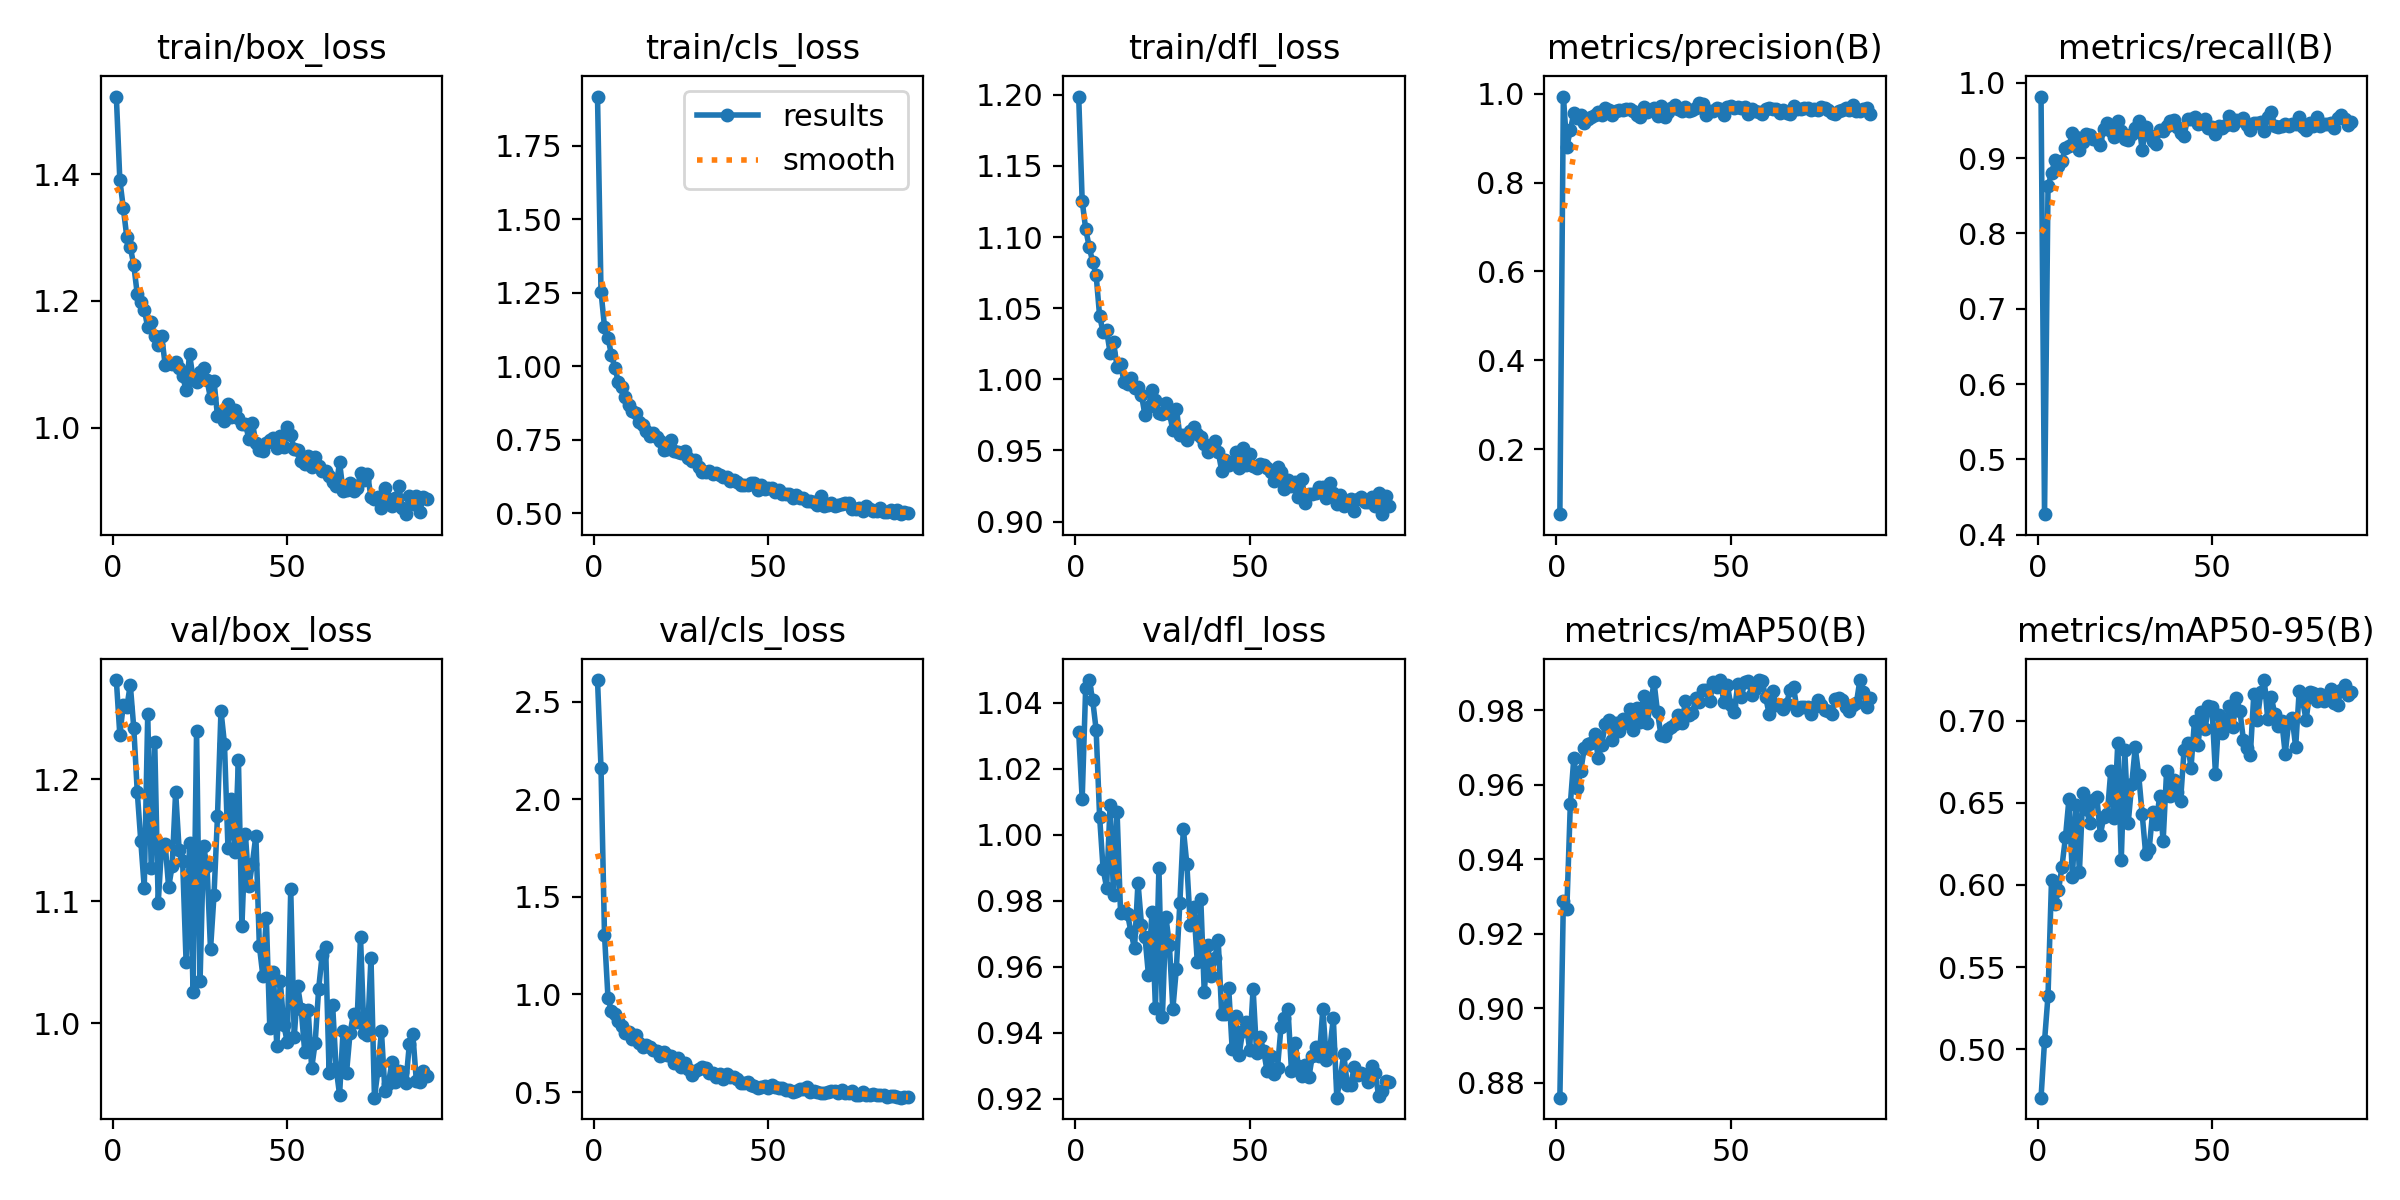

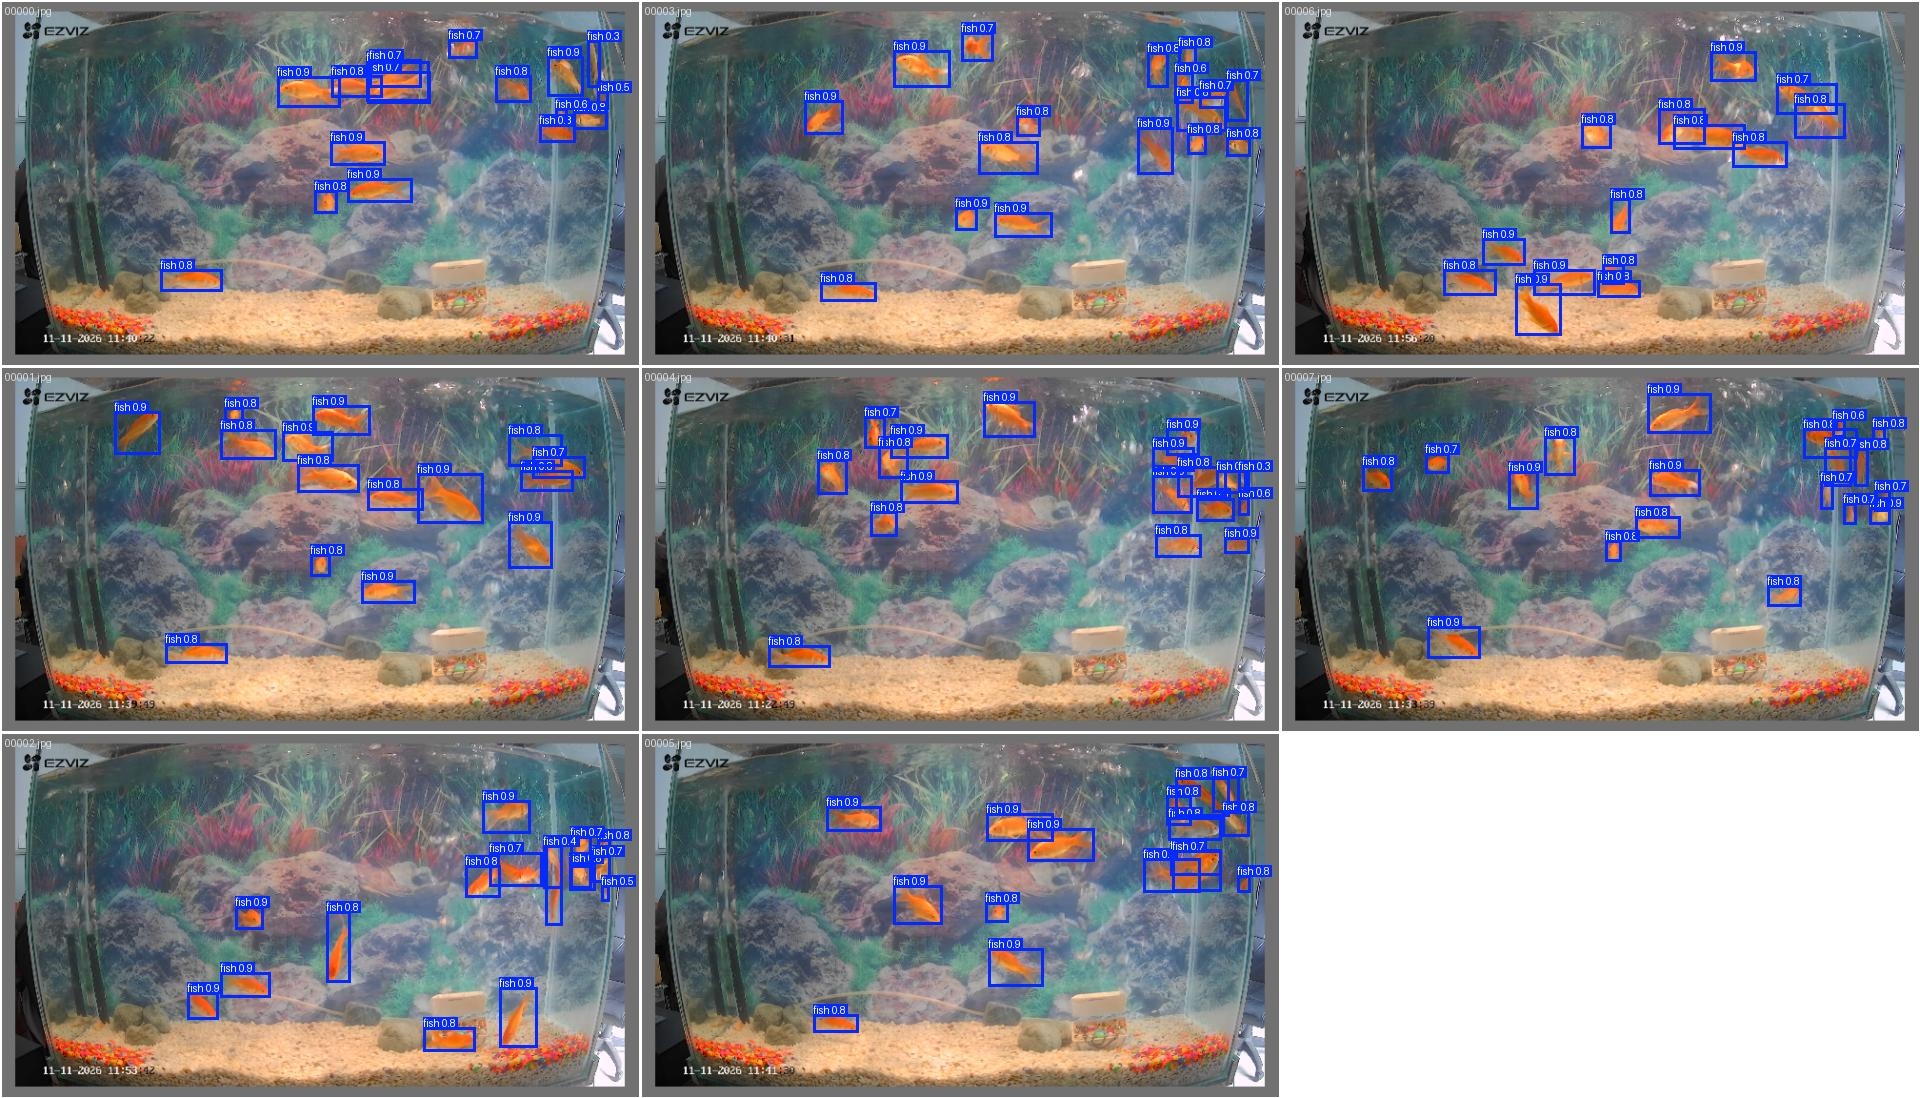

In [5]:
run = Path(best_checkpoint).parent.parent
for name in ["results.png", "val_batch0_pred.jpg"]:
    path = run / name
    if path.exists(): display(Image(filename=str(path)))

## Completed run

CUDA training completed after 90 epochs with early stopping.

| Metric | Validation | Test |
|---|---:|---:|
| Precision | 96.42% | 94.12% |
| Recall | 93.68% | 95.26% |
| mAP50 | 98.45% | 98.48% |
| mAP50-95 | 72.72% | 72.45% |

The best checkpoint is `results/fish_detector/weights/best.pt`. Review `results/Training_Report.md` for dataset limitations. These scores describe held-out images from the same aquarium; independent recording sessions are needed to establish broader performance.